# Atelier 2 — Partie 2 : Vision Transformer depuis zéro

**Auteur : KARMAS Hammam**

Ce notebook implémente la logique du ViT puis le compare aux modèles de la partie 1.
Il réutilise le même protocole. Les sorties du dépôt sont des vérifications CPU ;
le profil complet exige un GPU Colab. Exécuter les deux notebooks pour obtenir
les cinq résultats complets, ou utiliser la commande CLI indiquée plus bas.

Le tutoriel du sujet sert de référence pédagogique. L'implémentation locale est
originale : aucun backbone ViT préentraîné, ni timm, ni TransformerEncoder tout fait.

In [1]:
from pathlib import Path
import importlib.util
import os
import subprocess
import sys

# Local : reconnaître la racine du dépôt ou son dossier notebooks/.
ROOT = Path.cwd()
if not (ROOT / 'src' / 'models.py').exists() and (ROOT.parent / 'src' / 'models.py').exists():
    ROOT = ROOT.parent
if not (ROOT / 'src' / 'models.py').exists():
    # Colab : le notebook ouvert depuis GitHub ne clone pas les autres fichiers.
    ROOT = Path('/content/Atelier2_DeepLearning')
    if not ROOT.exists():
        subprocess.run(['git', 'clone', 'https://github.com/KarmasHammam/Atelier2_DeepLearning.git', str(ROOT)], check=True)
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

# Conserver le PyTorch CUDA fourni par Colab ; ne jamais installer une roue CPU ici.
if importlib.util.find_spec('google') and importlib.util.find_spec('google.colab'):
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', '-r', 'requirements-colab.txt'])

import json
import pandas as pd
import torch
import torchvision
from IPython.display import display, Image
from src.config import configuration
from src.train import run
from src.explore import explore
from src.compare import compare

PROFILE = 'full' if torch.cuda.is_available() else 'smoke'
DEVICE = 'cuda' if PROFILE == 'full' else 'cpu'
print('PyTorch :', torch.__version__, '| torchvision :', torchvision.__version__)
print('Profil :', PROFILE, '| Matériel :', torch.cuda.get_device_name(0) if PROFILE == 'full' else 'CPU')
if PROFILE == 'smoke':
    print('ATTENTION : vérification CPU sur 64 images de train, 40 de validation, 80 de test, une époque.')
    print('Les scores affichés NE SONT PAS les résultats finaux GPU demandés par le sujet.')
else:
    # Vérifier les opérations de détection CUDA avant un long entraînement.
    torchvision.ops.nms(torch.tensor([[0., 0., 2., 2.]], device='cuda'),
                        torch.tensor([.9], device='cuda'), .5)
    print('Expérience complète : 54 000 train, 6 000 validation, 10 000 test.')


def show_result(result):
    folder = ROOT / 'results' / PROFILE / result['model']
    print(result['model'], '|', result['purpose'])
    display(pd.DataFrame([{
        'accuracy test': result['test']['accuracy'], 'F1 macro test': result['test']['f1_macro'],
        'loss propre au modèle': result['test']['loss'],
        'temps train (s)': result['training_seconds'], 'époque choisie sur validation': result['selected_epoch'],
        'paramètres entraînables': result['trainable_parameters'],
    }]))
    display(Image(filename=str(folder / 'learning_curves.png')))
    display(Image(filename=str(folder / 'confusion_matrix.png')))
    display(pd.read_csv(folder / 'classification_report.csv', index_col=0))

PyTorch : 2.14.1+cpu | torchvision : 0.29.2+cpu
Profil : smoke | Matériel : CPU
ATTENTION : vérification CPU sur 64 images de train, 40 de validation, 80 de test, une époque.
Les scores affichés NE SONT PAS les résultats finaux GPU demandés par le sujet.


## Comprendre les données et le protocole commun

MNIST contient 60 000 images d'apprentissage et 10 000 images de test, en niveaux
 de gris, de taille 28×28. Le train officiel est séparé en **54 000 train et 6 000
validation**, de manière stratifiée, avec la graine 42. Les cinq modèles utilisent
les mêmes indices. Le test officiel reste réservé à l'évaluation finale.

Le miroir GitHub fournit les fichiers IDX MNIST standard. Les empreintes MD5
attendues par torchvision sont conservées ; le téléchargement ne dépend pas d'une
clé Kaggle. La source demandée par le sujet reste indiquée dans le README.

L'augmentation géométrique du profil complet agit uniquement sur le train :
rotation jusqu'à 10° et translation jusqu'à 5 %. Les sondes de train, la validation
et le test ne sont pas augmentés. Les statistiques de normalisation sont des
constantes MNIST/ImageNet fixées, pas des valeurs estimées sur le test.

EDA enregistrée dans results/eda/.


,train,validation,test
chiffre,,,
0,5331,592,980
1,6068,674,1135
2,5362,596,1032
3,5518,613,1010
4,5258,584,982
5,4879,542,892
6,5326,592,958
7,5638,627,1028
8,5266,585,974


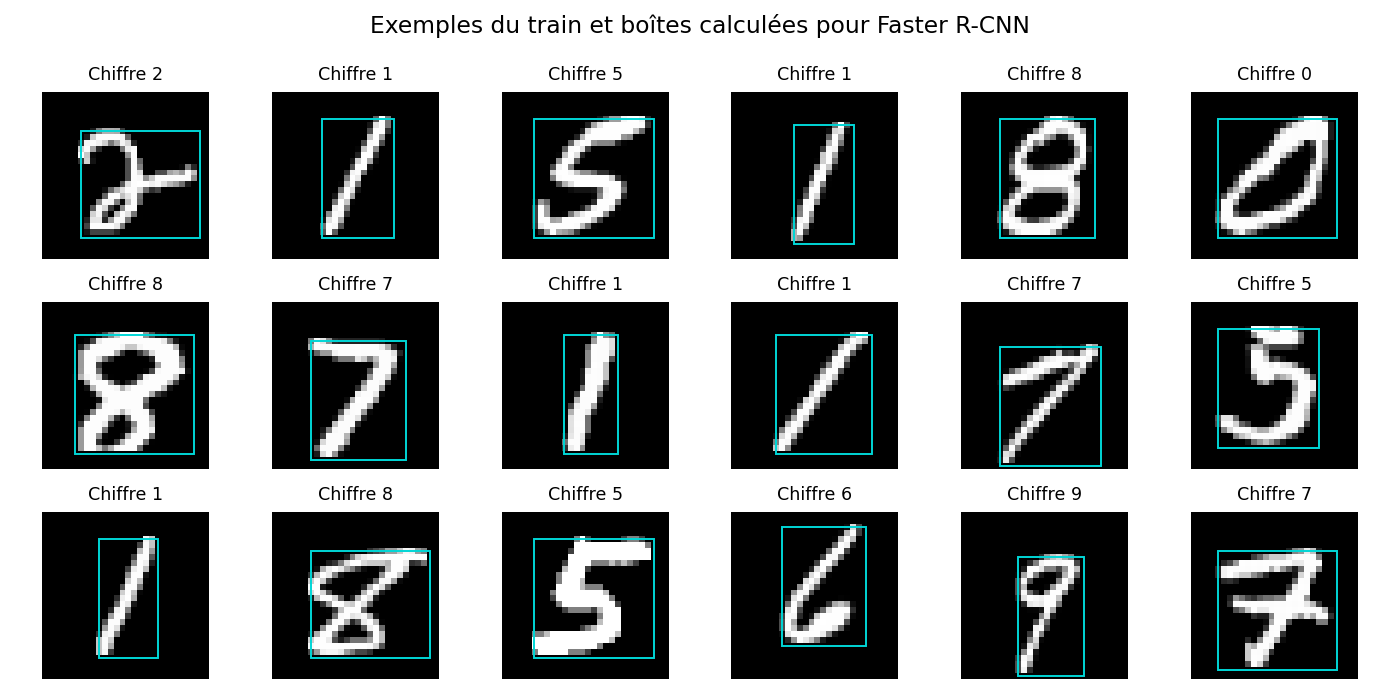

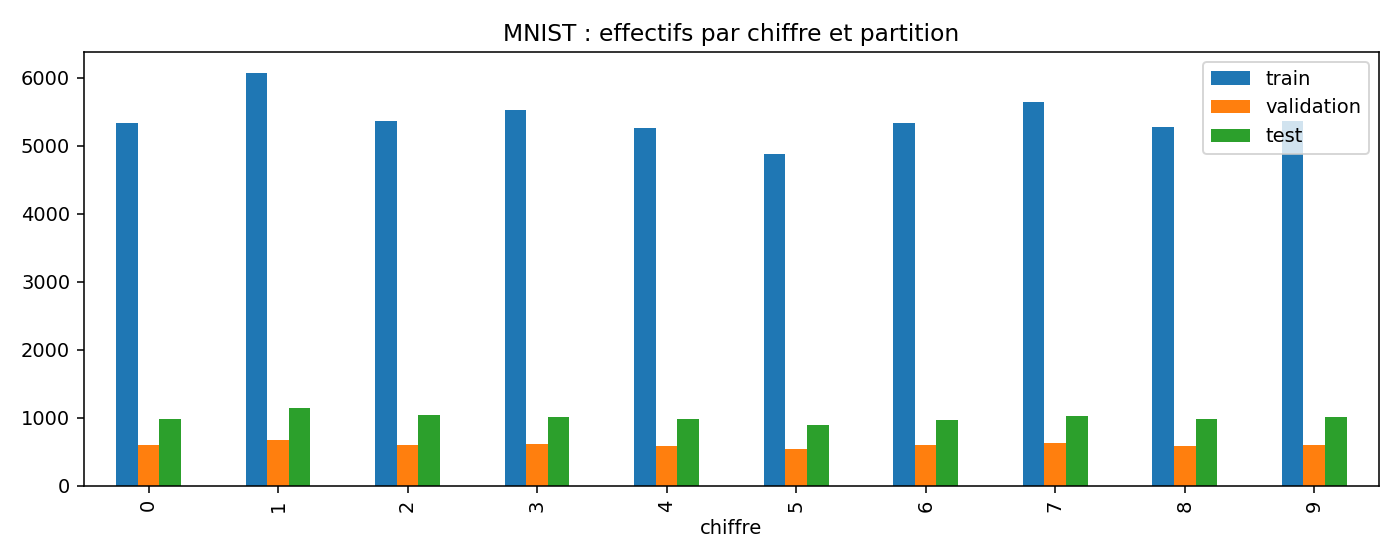

In [2]:
explore()
display(pd.read_csv(ROOT / 'results/eda/class_counts.csv', index_col=0))
display(Image(filename=str(ROOT / 'results/eda/examples_boxes.png')))
display(Image(filename=str(ROOT / 'results/eda/class_counts.png')))

## 1. Transformer une image en séquence

Une image 28×28 est divisée en **16 patches de 7×7**. Chaque patch contient
49 valeurs, projetées par une couche linéaire vers 64 dimensions. Un token
apprenable **CLS** résume l'image ; une position apprise indique l'emplacement
des patches. La séquence comporte donc 17 tokens.

Trois blocs encodeurs appliquent une normalisation, une attention à quatre têtes,
une connexion résiduelle et un MLP avec GELU. L'attention est calculée explicitement :
**softmax(QKᵀ / √d) V**. Les têtes regardent différentes relations entre patches.
La représentation finale du token CLS alimente une tête à dix logits.

In [3]:
from src.models import ViT
model_example = ViT()
display(model_example)
print('Forme des positions :', tuple(model_example.position.shape))
print('Sortie sur deux images :', tuple(model_example(torch.randn(2, 1, 28, 28)).shape))
del model_example

ViT(
  (unfold): Unfold(kernel_size=7, dilation=1, padding=0, stride=7)
  (embedding): Linear(in_features=49, out_features=64, bias=True)
  (blocks): Sequential(
    (0): EncoderBlock(
      (norm1): LayerNorm((64,), eps=1e-05, elementwise_affine=True, bias=True)
      (norm2): LayerNorm((64,), eps=1e-05, elementwise_affine=True, bias=True)
      (attention): Attention(
        (qkv): Linear(in_features=64, out_features=192, bias=True)
        (projection): Linear(in_features=64, out_features=64, bias=True)
        (dropout): Dropout(p=0.1, inplace=False)
      )
      (mlp): Sequential(
        (0): Linear(in_features=64, out_features=128, bias=True)
        (1): GELU(approximate='none')
        (2): Dropout(p=0.1, inplace=False)
        (3): Linear(in_features=128, out_features=64, bias=True)
        (4): Dropout(p=0.1, inplace=False)
      )
    )
    (1): EncoderBlock(
      (norm1): LayerNorm((64,), eps=1e-05, elementwise_affine=True, bias=True)
      (norm2): LayerNorm((64,), eps

Forme des positions : (1, 17, 64)
Sortie sur deux images : (2, 10)


## 2. Entraîner le ViT

Le profil complet utilise AdamW, un taux de 0,0003, weight_decay=0,01,
12 époques et des lots de 128. Le Dropout vaut 0,1 dans les blocs.
Le meilleur checkpoint est sélectionné au F1 macro de validation.

Un ViT n'a pas le même biais local qu'un CNN. Il peut nécessiter davantage de
données ou de réglages. Cela constitue une hypothèse d'interprétation ; les
résultats complets détermineront ce qui est observé dans cette expérience.

Config(model='vit', profile='smoke', seed=42, epochs=1, batch_size=4, lr=0.0003, weight_decay=0.01, train_size=64, valid_size=40, test_size=80, probe_size=40, augmentation=False, pretrained=False)
vit : résultat existant réutilisé (smoke).


vit | CPU functional smoke check, NOT final GPU evidence


,accuracy test,F1 macro test,loss propre au modèle,temps train (s),époque choisie sur validation,paramètres entraînables
0,0.2,0.113822,2.259145,0.114871,1,105546


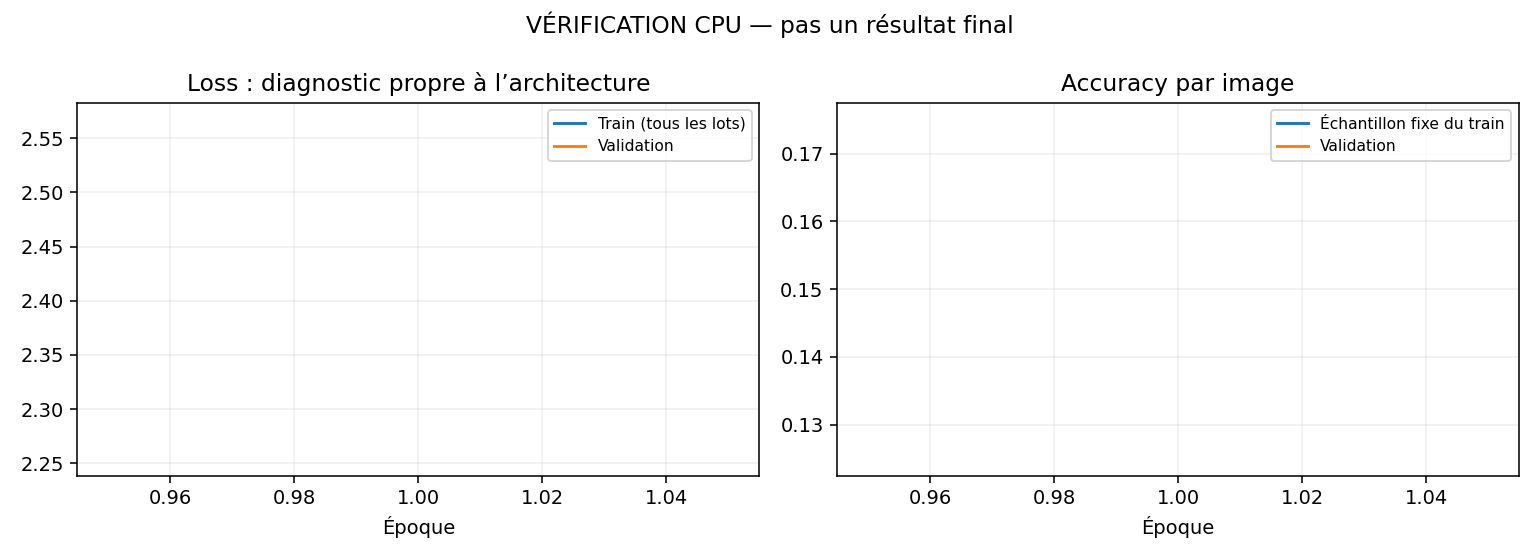

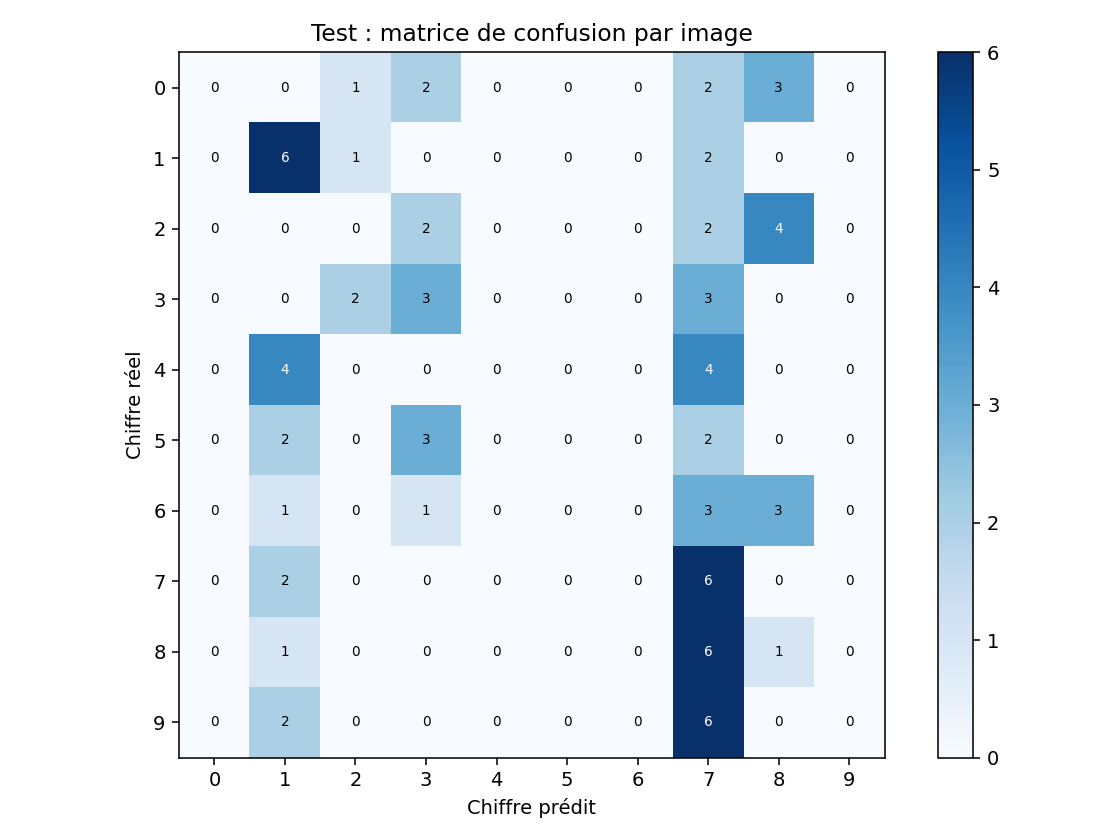

,precision,recall,f1-score,support
0,0.000000,0.000000,0.000000,8.0
1,0.333333,0.666667,0.444444,9.0
2,0.000000,0.000000,0.000000,8.0
3,0.272727,0.375000,0.315789,8.0
4,0.000000,0.000000,0.000000,8.0
5,0.000000,0.000000,0.000000,7.0
6,0.000000,0.000000,0.000000,8.0
7,0.166667,0.750000,0.272727,8.0
8,0.090909,0.125000,0.105263,8.0
9,0.000000,0.000000,0.000000,8.0


In [4]:
print(configuration('vit', PROFILE))
vit_result = run('vit', profile=PROFILE, device_name=DEVICE)
show_result(vit_result)

## 3. Finaliser les cinq expériences dans cette session

Si les résultats de la première partie ne sont pas présents dans cette session
Colab, la cellule suivante entraîne les modèles manquants. Les résultats déjà
terminés et compatibles sont réutilisés. Le tableau final n'est créé que si les
cinq modèles ont terminé sur les mêmes partitions et le même profil.

cnn : résultat existant réutilisé (smoke).


fasterrcnn : résultat existant réutilisé (smoke).


vgg16 : résultat existant réutilisé (smoke).


alexnet : résultat existant réutilisé (smoke).


vit : résultat existant réutilisé (smoke).


     model profile device  accuracy  f1_macro     loss       loss_type  training_seconds  epochs  selected_epoch  parameters  trainable_parameters  test_images  same_hardware
       cnn   smoke    CPU    0.3625  0.276415 2.246681   cross_entropy          0.129991       1               1      421642                421642           80           True
fasterrcnn   smoke    CPU    0.2625  0.167564 0.283803 detection_total         26.009766       1               1    41345286              41122886           80           True
     vgg16   smoke    CPU    0.2625  0.215854 2.160725   cross_entropy         14.000007       1               1   134301514               7120394           80           True
   alexnet   smoke    CPU    0.2750  0.227718 2.126278   cross_entropy          1.066578       1               1    57044810                631050           80           True
       vit   smoke    CPU    0.2000  0.113822 2.259145   cross_entropy          0.114871       1               1      105546 

,model,profile,device,accuracy,f1_macro,loss,loss_type,training_seconds,epochs,selected_epoch,parameters,trainable_parameters,test_images,same_hardware
0,cnn,smoke,CPU,0.3625,0.276415,2.246681,cross_entropy,0.129991,1,1,421642,421642,80,True
1,fasterrcnn,smoke,CPU,0.2625,0.167564,0.283803,detection_total,26.009766,1,1,41345286,41122886,80,True
2,vgg16,smoke,CPU,0.2625,0.215854,2.160725,cross_entropy,14.000007,1,1,134301514,7120394,80,True
3,alexnet,smoke,CPU,0.2750,0.227718,2.126278,cross_entropy,1.066578,1,1,57044810,631050,80,True
4,vit,smoke,CPU,0.2000,0.113822,2.259145,cross_entropy,0.114871,1,1,105546,105546,80,True


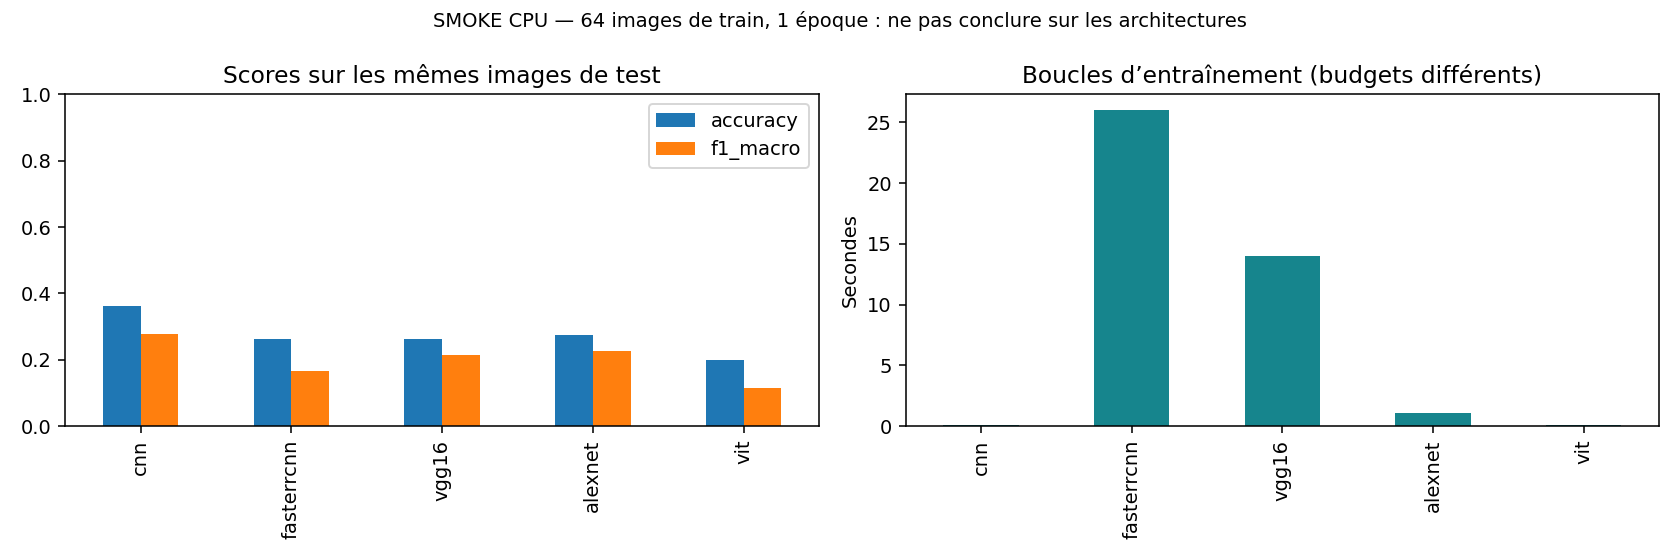

In [5]:
from src.config import MODELS
for name in MODELS:
    run(name, profile=PROFILE, device_name=DEVICE)
comparison = compare(PROFILE)
display(comparison)
display(Image(filename=str(ROOT / 'results' / PROFILE / 'comparison.png')))

## 4. Interpréter la comparaison

Comparer accuracy et F1 macro sur les mêmes images, puis regarder les confusions
par chiffre. Relier les différences aux paramètres entraînables, au préentraînement,
aux tailles d'entrée et aux budgets d'époques. Les losses sont diagnostiques :
la somme des pertes de détection ne mesure pas la même chose qu'une entropie croisée.

La comparaison des temps n'est pertinente qu'en tenant compte du matériel.
Les époques sont volontairement différentes entre les architectures ; le tableau
ne constitue pas un benchmark à temps ou à nombre de mises à jour égaux.

**La conclusion académique finale reste à compléter avec les résultats GPU.**
Les sorties CPU affichées ici ne permettent pas de déclarer un modèle supérieur.

In [6]:
from scripts.export_results import export
archive = export(PROFILE)
print('Archive à conserver :', archive.name)
try:
    from google.colab import files
    files.download(str(archive))
except ImportError:
    print('Exécution locale : archive disponible à la racine du dépôt.')

     model profile device  accuracy  f1_macro     loss       loss_type  training_seconds  epochs  selected_epoch  parameters  trainable_parameters  test_images  same_hardware
       cnn   smoke    CPU    0.3625  0.276415 2.246681   cross_entropy          0.129991       1               1      421642                421642           80           True
fasterrcnn   smoke    CPU    0.2625  0.167564 0.283803 detection_total         26.009766       1               1    41345286              41122886           80           True
     vgg16   smoke    CPU    0.2625  0.215854 2.160725   cross_entropy         14.000007       1               1   134301514               7120394           80           True
   alexnet   smoke    CPU    0.2750  0.227718 2.126278   cross_entropy          1.066578       1               1    57044810                631050           80           True
       vit   smoke    CPU    0.2000  0.113822 2.259145   cross_entropy          0.114871       1               1      105546 

/workspace/Atelier2_DeepLearning/resultats_atelier2_smoke.zip
Archive à conserver : resultats_atelier2_smoke.zip
Exécution locale : archive disponible à la racine du dépôt.


## 5. Synthèse des notions abordées

Cet atelier montre comment une convolution exploite les motifs locaux, comment
le transfert réutilise des caractéristiques apprises et comment un ViT relie des
patches par attention. L'adaptation de Faster R-CNN oblige à distinguer classification
et détection, ainsi qu'accuracy par image et qualité de localisation.

La synthèse personnelle finale doit décrire ce qui a été compris et les résultats
réellement obtenus sur GPU. Aucun résultat Colab n'est supposé à partir du profil CPU.

## Lire les résultats sans tirer une conclusion trop vite

- L'accuracy mesure la proportion de chiffres corrects ; le F1 macro donne le même
  poids à chaque chiffre. Le rapport détaille précision, rappel, F1 et support.
- Les courbes d'accuracy du train utilisent une **sonde fixe** de 1 000 images dans
  le profil complet, ou 40 dans le profil smoke. La loss train utilise tous les lots.
- Le checkpoint est choisi au meilleur F1 macro de validation. Le test n'est calculé
  qu'après ce choix ; ses scores n'influencent ni les gradients ni l'époque retenue.
- Faster R-CNN additionne plusieurs pertes ; sa loss n'est pas directement
  comparable à l'entropie croisée des classifieurs.
- Les budgets d'époques, les tailles d'entrée et les paramètres entraînables
  diffèrent : le temps mesuré est descriptif, pas un classement à budget égal.
- Un score smoke de CPU ne permet aucune conclusion sur la supériorité d'un modèle.
  La conclusion finale devra être fondée sur les cinq exécutions **full GPU**.

### Conserver les résultats Colab sur GitHub

Dans Colab : **Fichier → Enregistrer une copie dans GitHub**, en conservant les
sorties des cellules. Le second notebook permet aussi d'exporter les CSV, JSON et
figures dans une archive à télécharger. Les poids et les clés d'accès ne sont pas
inclus dans cette archive. Ne publier que des sorties réellement exécutées.